# Axis 1 — AI adoption and profiles

## The mission and working context
**Question:** how does reported AI use vary by professional experience and role?

The educational sponsor is a DINUM team preparing an AI coding-assistant pilot. This axis helps the team decide which profiles to include in onboarding. These survey respondents are not DINUM employees, so the results are starting points for a pilot, not a staffing recommendation.

Sub-questions:
- How many eligible respondents give a usable answer about AI use?
- Does reported use differ across experience groups?
- Is the pattern similar within a common role and among employed respondents?

## Step 1 — Data and population
The 2026 public response file has one row per respondent, identified by `ResponseId`. The schema describes the questions; it is a reference table and is not joined to the responses. No join between people is needed.

We keep respondents in France who say creating code is a primary part of their job, across all industries. The shared preparation function applies this rule. The fields used are:

| Field | Use in this axis |
|---|---|
| `ResponseId` | Identify respondents and check the unit of observation |
| `Country`, `CodeMain` | Define the eligible population |
| `WorkExp` | Total professional experience, not just coding experience |
| `Role` | Describe roles and restrict the robustness comparison |
| `Employment` | Restrict the comparison to employed respondents |
| `AISelect` | Identify current AI use at work; multiple selections are allowed |

Source files: `data/raw/2026/survey_results_public.csv` and `survey_results_schema.csv`, downloaded from the [official 2026 archive](https://github.com/StackExchange/Survey/tree/main/packages/archive/2026). The [official results](https://survey.stackoverflow.co/2026) provide the wider survey context; our figures below are calculated from the public response file for our own population.

`ai_user` is True for at least one recognised category: coding assistants/agents, general-purpose AI chat, AI agents/automated workflows, or internal company AI tools. It is False for explicit non-use alone. Missing, unrecognised or contradictory answers stay unknown. Experience outside 0–80 years is treated as unknown, following the common plausibility rule; this is a cleaning choice, not a verified correction of the original answer. These are volunteers, and unanswered questions may bias comparisons. Role refers to the current role or the role held longest during the past year; student and unemployed categories can therefore appear in this population.

Data access and dependencies: follow the repository README (`uv sync --locked --group exploration` and `uv run python scripts/download_data.py`). Start Jupyter with `uv run jupyter lab`. All paths below are relative to the project, and downloaded data stays outside Git.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "pyproject.toml").exists() and (p / "src/population.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data import load_responses, load_schema
from src.population import prepare_population
from axes.axis_1.analysis import with_career_groups, adoption_table, subgroup_comparison

responses = load_responses()
population = prepare_population(responses)
population_flow = pd.DataFrame({
    "population": ["All survey respondents", "Respondents in France", "France: coding as a primary part of the job"],
    "respondents_n": [len(responses), responses.Country.eq("France").sum(), len(population)]
})
display(population_flow)
print("Year: 2026; no additional role, experience or employment filter is applied.")
print(f"Unique respondent IDs: {population['ResponseId'].nunique()}")

,population,respondents_n
0,All survey respondents,30903
1,Respondents in France,794
2,France: coding as a primary part of the job,628


Year: 2026; no additional role, experience or employment filter is applied.
Unique respondent IDs: 628


## Step 2 — I notice, I wonder
First check coverage, then compare experience and role. The rate is the number of AI users divided by respondents with a usable AI-use answer, not all selected respondents. AI use includes general-purpose chat tools as well as coding assistants; it does not measure coding-assistant use alone.

In [2]:
coverage = pd.DataFrame({
    "field": ["AI-use indicator", "Professional experience", "Role"],
    "selected_n": [len(population)] * 3,
    "usable_n": [population.ai_user.notna().sum(),
                 population.experience_years.notna().sum(), population.Role.notna().sum()]
})
coverage["unknown_n"] = coverage.selected_n - coverage.usable_n
display(coverage)
known = population.ai_user.dropna()
print(f"Reported AI use: {int(known.sum())}/{len(known)} = {known.mean():.1%}")

raw_ai_answered = population.AISelect.notna() & population.AISelect.fillna("").str.strip().ne("")
raw_years = pd.to_numeric(population.WorkExp, errors="coerce")
print("AI-use answers missing or empty:", int((~raw_ai_answered).sum()))
print("AI-use answers present but excluded by the shared validity rule:",
      int((raw_ai_answered & population.ai_user.isna()).sum()))
print("Experience missing or non-numeric:", int(raw_years.isna().sum()))
print("Experience outside the accepted range:", int((raw_years.notna() & ~raw_years.between(0, 80)).sum()))

schema = load_schema()
display(schema.loc[schema.column.isin(["AISelect", "WorkExp", "Role", "Employment"]),
                   ["column", "question"]].reset_index(drop=True))

,field,selected_n,usable_n,unknown_n
0,AI-use indicator,628,507,121
1,Professional experience,628,607,21
2,Role,628,627,1


Reported AI use: 388/507 = 76.5%
AI-use answers missing or empty: 118
AI-use answers present but excluded by the shared validity rule: 3
Experience missing or non-numeric: 20
Experience outside the accepted range: 1


,column,question
0,Employment,Which of the following best describes your cur...
1,WorkExp,How many years have you been working professio...
2,Role,Which of the following best describes your cur...
3,AISelect,Do you currently use AI tools or AI agents in ...


,selected_n,answered_n,users_n,answer_pct,use_pct
experience_group,,,,,
0–2 years,76,64,42,84.2,65.6
3–5 years,94,71,51,75.5,71.8
6–10 years,139,107,84,77.0,78.5
11–20 years,196,162,125,82.7,77.2
21–80 years,102,84,69,82.4,82.1


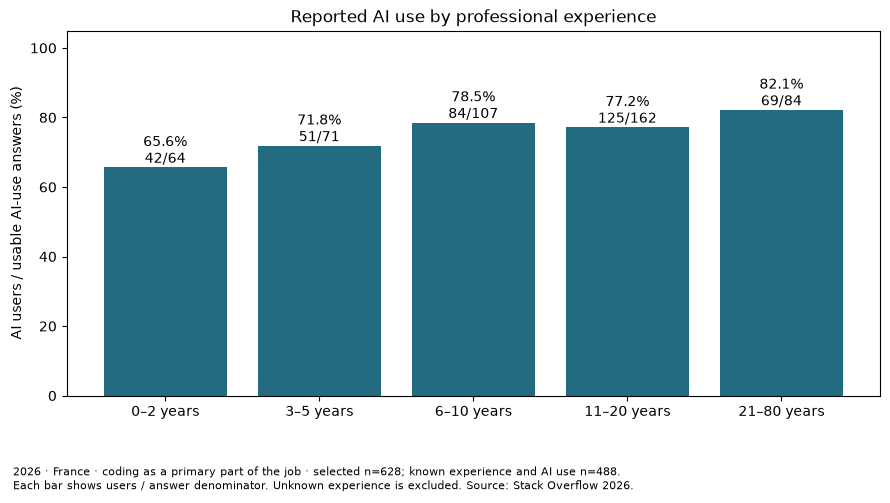

In [3]:
experience = adoption_table(population, "experience_group")
display(experience[["selected_n", "answered_n", "users_n", "answer_pct", "use_pct"]].round(1))

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(experience.index.astype(str), experience.use_pct.astype(float), color="#226B80")
ax.bar_label(bars, labels=[f"{p:.1f}%\n{int(u)}/{n}" for p, u, n in
                         zip(experience.use_pct, experience.users_n, experience.answered_n)])
ax.set(ylim=(0, 105), ylabel="AI users / usable AI-use answers (%)",
       title="Reported AI use by professional experience")
fig.text(.02, .01, f"2026 · France · coding as a primary part of the job · selected n={len(population)}; "
         f"known experience and AI use n={int(experience.answered_n.sum())}.\n"
         "Each bar shows users / answer denominator. Unknown experience is excluded. Source: Stack Overflow 2026.", fontsize=8)
fig.tight_layout(rect=(0, .12, 1, 1))
plt.show()

**I notice:** use is 42/64 (65.6%) in the 0–2 years group and 69/84 (82.1%) in the 21–80 years group. The progression is not strictly increasing. Some selected people do not answer the AI question, and 21 have unknown or implausible experience.

**I wonder:** could the difference reflect the mix of roles rather than experience? Could the pattern change when we keep employed respondents only?

In [4]:
roles = adoption_table(population, "Role")
display(roles.loc[roles.answered_n >= 20, ["selected_n", "answered_n", "users_n", "use_pct"]]
        .sort_values("answered_n", ascending=False).round(1))
print("Roles with fewer than 20 usable AI-use answers:", int((roles.answered_n < 20).sum()))

,selected_n,answered_n,users_n,use_pct
Role,,,,
"Developer, full-stack",236,181,142,78.5
"Developer, back-end",82,68,51,75.0
"Architect, software or solutions",53,42,35,83.3
Student,31,28,21,75.0
"Developer, desktop or enterprise applications",36,25,18,72.0


Roles with fewer than 20 usable AI-use answers: 32


**I notice:** full-stack developers form the largest role group (181 usable AI-use answers). Many other roles have fewer than 20 answers, so their percentages would be unstable. A minimum of 20 usable answers is a simple display rule to avoid highlighting tiny groups; it is not a guarantee of precision. This table describes roles with enough answers; it does not rank all French occupations.

**I wonder:** does the experience difference remain within full-stack developers? We can examine that group without combining unrelated roles.

## Step 3 — Comparison to investigate
**Hypothesis:** among respondents with known professional experience and a usable AI-use answer, reported AI use is higher for those with 6 or more years of experience than for those with 0–5 years.

This threshold summarises the exploratory groups into an early-career group and a more experienced group. It was chosen after exploration: this is a descriptive follow-up, not an independent confirmatory test. We will show group sizes and answer coverage, check the same comparison among full-stack developers and employed respondents, and discuss missing answers before drawing a conclusion.

### A clear comparison
The two groups are **0–5 years** and **6+ years** of total professional experience. Respondents with unknown experience are excluded from this comparison. Within each group, the AI-use rate uses only usable AI-use answers. We report the percentage-point difference (6+ minus 0–5), together with the counts and answer coverage. This is an evidence-based descriptive comparison, without a significance test or causal claim.

,selected_n,answered_n,users_n,unknown_n,answer_pct,use_pct
career_group,,,,,,
0–5 years,170,135,93,35,79.4,68.9
6+ years,437,353,278,84,80.8,78.8


Observed difference (6+ minus 0–5): 9.9 percentage points


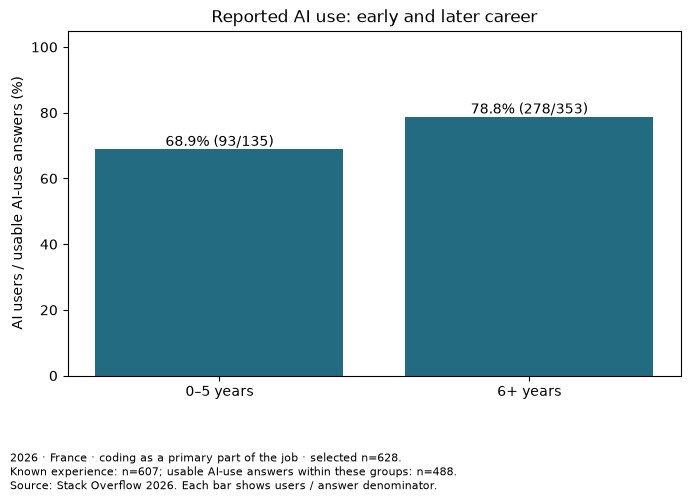

In [5]:
axis_population = with_career_groups(population)
comparison = adoption_table(axis_population, "career_group")
display(comparison[["selected_n", "answered_n", "users_n", "unknown_n", "answer_pct", "use_pct"]].round(1))
gap = comparison.loc["6+ years", "use_pct"] - comparison.loc["0–5 years", "use_pct"]
print(f"Observed difference (6+ minus 0–5): {gap:.1f} percentage points")

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(comparison.index.astype(str), comparison.use_pct.astype(float), color="#226B80")
ax.bar_label(bars, labels=[f"{p:.1f}% ({int(u)}/{n})" for p, u, n in
                         zip(comparison.use_pct, comparison.users_n, comparison.answered_n)])
ax.set(ylim=(0, 105), ylabel="AI users / usable AI-use answers (%)",
       title="Reported AI use: early and later career")
fig.text(.02, .01, f"2026 · France · coding as a primary part of the job · selected n={len(population)}.\n"
         f"Known experience: n={int(comparison.selected_n.sum())}; usable AI-use answers within these groups: "
         f"n={int(comparison.answered_n.sum())}.\nSource: Stack Overflow 2026. Each bar shows users / answer denominator.", fontsize=8)
fig.tight_layout(rect=(0, .16, 1, 1))
plt.show()

**Result:** 278/353 (78.8%) of respondents with 6+ years report AI use, compared with 93/135 (68.9%) among those with 0–5 years: a difference of **9.9 percentage points**. This supports the direction of the hypothesis in the observed answers. Coverage is 80.8% and 79.4% respectively, so similar coverage does not mean there is no non-response bias.

### Alternative explanations and robustness
Role and employment status may be related to both experience and AI use. We repeat the same calculation within the largest role (full-stack developers) and among people selecting `Employed`. These are separate restrictions, not a full adjustment for all differences.

In [6]:
checks = subgroup_comparison(axis_population)
display(checks.round(1))
print("2026 · France · coding as a primary part of the job. Each rate uses its row's answer count.")
print("Subgroups overlap; do not add their counts. Unknown experience is excluded.")

,Population,Selected n,Known experience n,0–5 users n,0–5 answers n,0–5 use (%),6+ users n,6+ answers n,6+ use (%),Difference (pp)
0,Current selection,628,607,93,135,68.9,278,353,78.8,9.9
1,Full-stack developers only,236,230,34,46,73.9,102,129,79.1,5.2
2,Employed respondents only,463,461,63,88,71.6,221,279,79.2,7.6


2026 · France · coding as a primary part of the job. Each rate uses its row's answer count.
Subgroups overlap; do not add their counts. Unknown experience is excluded.


**I notice:** the difference remains positive within full-stack developers (5.2 points: 102/129 versus 34/46) and among employed respondents (7.6 points: 221/279 versus 63/88). It is smaller than the overall difference.

**Interpretation:** the smaller differences are consistent with a possible role or employment composition effect, but do not demonstrate one. These checks do not isolate the effect of experience. The smaller subgroups also make the estimates less stable.

### What if people with unknown AI use answered differently?
For each experience group, the lower scenario treats every unknown AI-use answer as non-use; the upper scenario treats every unknown as use. The denominator is now **all selected people in that experience group**. These extreme scenarios are a sensitivity check, not estimates or confidence intervals.

In [7]:
display(comparison[["selected_n", "unknown_n", "lower_pct", "upper_pct"]].round(1))

,selected_n,unknown_n,lower_pct,upper_pct
career_group,,,,
0–5 years,170,35,54.7,75.3
6+ years,437,84,63.6,82.8


### What this supports and what remains uncertain
The ranges overlap: 54.7–75.3% for 0–5 years and 63.6–82.8% for 6+ years. Different behaviour among people with unknown answers could change the observed ordering. Experience is also unknown for 21 eligible respondents, who are not represented in this comparison. There are 488 usable AI-use answers among the 607 people with known experience; this is why the comparison denominator is smaller than the 507 usable AI-use answers in the full eligible population.

For the DINUM pilot, a reasonable next step is to include both early-career and experienced participants and check their onboarding needs locally. The lower observed use among early-career respondents suggests a question to investigate, not proof that they need more training.

We cannot conclude that experience causes AI adoption, that AI use improves productivity, or that these percentages describe DINUM staff or all French developers. AI use here includes tools beyond coding assistants. The threshold and hypothesis came from this same exploration, and there is no 2025 comparison. A pilot should collect its own usage and support feedback before making a wider decision.